## Question 1: Image Preprocessing for Inference (PyTorch)
### Question
**Problem:** Write a function to load an image and preprocess it for inference.

### Answer

In [6]:
# Run once if needed, then you can comment it out:
# !pip install torch torchvision

import os
from PIL import Image
from torchvision import transforms

# 1. Define the function FIRST
def preprocess_image(image_path):
    # Explanation: open the image and convert to RGB (3 channels),
    # because some images are grayscale or have 4 channels (RGBA)
    image = Image.open(image_path).convert("RGB")

    transform = transforms.Compose([
        # Explanation: pretrained models (ResNet, VGG etc.) expect 224 x 224
        transforms.Resize((224, 224)),
        # Explanation: converts to a tensor (3, 224, 224) and scales 0-255 -> 0-1
        transforms.ToTensor(),
        # Explanation: normalize with ImageNet mean and std for R, G, B
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])

    # Explanation: unsqueeze(0) adds the batch dimension -> (1, 3, 224, 224),
    # because models always take a batch of images
    return transform(image).unsqueeze(0)


# 2. See where Jupyter is looking and which images are there
print("Current folder:", os.getcwd())
print("Images here:", [f for f in os.listdir() if f.lower().endswith((".jpg", ".jpeg", ".png"))])


# 3. Put YOUR real image path here
path = "test.jpg"   # or e.g. r"C:\Users\Nishanth\Pictures\photo.jpg"

if os.path.exists(path):
    img_tensor = preprocess_image(path)
    print("Preprocessed shape:", img_tensor.shape)   # torch.Size([1, 3, 224, 224])
else:
    print("Image not found:", path)
    print("-> Copy an image into the current folder above, or paste its full path.")

Current folder: C:\HOPE AI\AI TAMIL COURSE\DEEP LEARNING SET QUESTIONS\4.Coding
Images here: []
Image not found: test.jpg
-> Copy an image into the current folder above, or paste its full path.


## Question 2: Predict on New Image with a Trained Model
### Question
**Problem:** Perform prediction and get the class label.

### Answer

In [9]:
import os
import urllib.request
import torch
from PIL import Image
from torchvision import models, transforms

# ---------- Get a test image ----------
# Downloads a sample dog photo and saves it as test.jpg
if not os.path.exists("test.jpg"):
    urllib.request.urlretrieve(
        "https://github.com/pytorch/hub/raw/master/images/dog.jpg", "test.jpg")
print("test.jpg is ready")

# ---------- Question 1: preprocess the image ----------
def preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])
    return transform(image).unsqueeze(0)

img_tensor = preprocess_image("test.jpg")
print("Preprocessed shape:", img_tensor.shape)

# ---------- Question 2: predict with ResNet18 ----------
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)
class_names = weights.meta["categories"]
model.eval()

with torch.no_grad():
    output = model(img_tensor)
    probabilities = torch.softmax(output, dim=1)
    predicted_class = output.argmax(1).item()
    confidence = probabilities[0, predicted_class].item()

print("Predicted Class ID   :", predicted_class)
print("Predicted Class Label:", class_names[predicted_class])
print(f"Confidence           : {confidence * 100:.2f}%")

test.jpg is ready
Preprocessed shape: torch.Size([1, 3, 224, 224])
Predicted Class ID   : 258
Predicted Class Label: Samoyed
Confidence           : 83.72%


## Question 3: Build a CNN to classify CIFAR-10 images (PyTorch)
### Question
**Problem:** Create a CNN model that classifies images from the CIFAR-10 dataset with accuracy above 60%.

### Answer

In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

# Explanation: use GPU if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Preprocessing
# Explanation: CIFAR-10 images have 3 channels, so we give mean/std for all 3
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# 2. Load data (downloads automatically the first time)
trainset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
testset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False)
classes = trainset.classes   # airplane, automobile, bird, cat, ...

# 3. CNN model
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv = nn.Sequential(
            # Explanation: 3 input channels (RGB) -> 32 feature maps; padding keeps size 32x32
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                 # 32x32 -> 16x16
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)                  # 16x16 -> 8x8
        )
        self.fc = nn.Sequential(
            # Explanation: 64 feature maps of size 8x8 = 64*8*8 inputs
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.3),                 # Explanation: reduces overfitting
            nn.Linear(128, 10)               # 10 classes
        )

    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)            # Explanation: flatten to (batch, 4096)
        return self.fc(x)

net = Net().to(device)
# Explanation: CrossEntropyLoss already includes softmax, so no softmax layer in the model
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters(), lr=0.001)

# 4. Training
# Explanation: the original trained only 1 epoch. 10 epochs are needed
# to reliably cross 60% accuracy (this model usually reaches about 70%).
EPOCHS = 10
for epoch in range(EPOCHS):
    net.train()
    running_loss = 0.0
    for images, labels in trainloader:
        images, labels = images.to(device), labels.to(device)
        outputs = net(images)                # forward pass
        loss = criterion(outputs, labels)
        optimizer.zero_grad()                # Explanation: clear old gradients
        loss.backward()                      # Explanation: calculate new gradients
        optimizer.step()                     # Explanation: update weights
        running_loss += loss.item()
    print(f"Epoch {epoch + 1}/{EPOCHS}  loss: {running_loss / len(trainloader):.4f}")

# 5. Test accuracy
# Explanation: the original answer never checked accuracy, so we could not
# confirm the "above 60%" requirement
net.eval()
correct, total = 0, 0
with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        predicted = net(images).argmax(1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Test Accuracy: {accuracy:.2f}%")
print("Target achieved (> 60%)" if accuracy > 60 else "Train for more epochs")

100%|██████████| 170M/170M [07:03<00:00, 403kB/s]    


Epoch 1/10  loss: 1.4427
Epoch 2/10  loss: 1.0921
Epoch 3/10  loss: 0.9599
Epoch 4/10  loss: 0.8713
Epoch 5/10  loss: 0.7980
Epoch 6/10  loss: 0.7309
Epoch 7/10  loss: 0.6772
Epoch 8/10  loss: 0.6269
Epoch 9/10  loss: 0.5795
Epoch 10/10  loss: 0.5308
Test Accuracy: 72.51%
Target achieved (> 60%)


## Question 4: Identify Overfitting from Training Logs and Solve It
### Question
**Problem:** You notice the training accuracy increases but validation accuracy stagnates. Modify the model using dropout and early stopping. (use mnist dataset)

### Answer

C:\Users\nisha\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 25ms/step - accuracy: 0.8782 - loss: 0.4031 - val_accuracy: 0.9642 - val_loss: 0.1218
Epoch 2/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.9485 - loss: 0.1751 - val_accuracy: 0.9760 - val_loss: 0.0862
Epoch 3/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9613 - loss: 0.1296 - val_accuracy: 0.9767 - val_loss: 0.0803
Epoch 4/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9688 - loss: 0.1025 - val_accuracy: 0.9797 - val_loss: 0.0717
Epoch 5/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9711 - loss: 0.0928 - val_accuracy: 0.9797 - val_loss: 0.0723
Epoch 6/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.9760 - loss: 0.0769 - val_accuracy: 0.9818 - val_loss: 0.0659
Epoch 7/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.9779 - loss: 0.0695 - val_accuracy: 0.9813 - val_loss: 0.0650
Epoch 8/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9789 - loss: 0.0643 - v

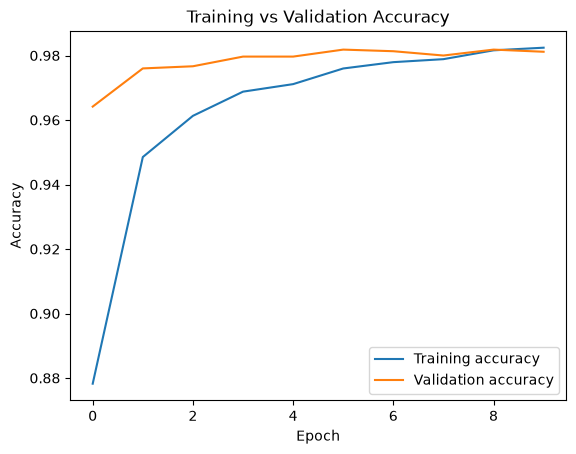

In [11]:
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

# 1. Load and prepare MNIST (28 x 28 handwritten digits, 10 classes)
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0          # scale to 0-1
y_train, y_test = to_categorical(y_train), to_categorical(y_test)

# Explanation: OVERFITTING = the model memorises the training data.
# Training accuracy keeps going up, but validation accuracy stops improving.
# Fix 1: Dropout  -> randomly switches off neurons so the model cannot memorise
# Fix 2: EarlyStopping -> stops training when validation stops improving

# 2. Model with Dropout
model = Sequential([
    Flatten(input_shape=(28, 28)),       # 28x28 image -> 784 values
    Dense(256, activation="relu"),
    Dropout(0.3),                        # Explanation: drop 30% of neurons during training
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(10, activation="softmax")      # 10 digits (0-9)
])

model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

# 3. Early stopping
# Explanation: watch validation loss; if it does not improve for 3 epochs,
# stop and go back to the best weights
early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

# 4. Train
# Explanation: validation_split=0.1 keeps 10% of training data for validation,
# so the test set stays unseen until the final evaluation
history = model.fit(x_train, y_train, validation_split=0.1,
                    epochs=30, batch_size=128, callbacks=[early_stop])

print("Stopped after", len(history.history["loss"]), "epochs")

# 5. Final test accuracy
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")

# 6. Plot training vs validation accuracy
# Explanation: if the two lines stay close, overfitting is under control
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

## Question 5: Transfer Learning with Pretrained VGG16 (Cats vs Dogs)
### Question
**Problem:** Use VGG16 for binary classification with fine-tuning.

### Answer

In [14]:
!pip install tensorflow-datasets

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
   ---------------------------------------- 0.0/5.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/5.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/5.3 MB ? eta -:--:--
   --- ------------------------------------ 0.5/5.3 MB 652.7 kB/s eta 0:00:08
   ----- ---------------------------------- 0.8/5.3 MB 867.3 kB/s eta 0:00:06
   ------- -------------------------------- 1.0/5.3 MB 964.4 kB/s eta 0:00:05
   --------- ------------------------------ 1.3/5.3 MB 990.2 kB/s eta 0:00:05
   ----------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
!pip install tensorflow tensorflow-datasets importlib_resources


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
import os, zipfile, io
from PIL import Image

# ---------- 1. Find the zip that TensorFlow Datasets already downloaded ----------
download_dir = os.path.join(os.path.expanduser("~"), "tensorflow_datasets", "downloads")
zip_path = None
for root, dirs, files in os.walk(download_dir):
    for f in files:
        p = os.path.join(root, f)
        # Explanation: the cats/dogs zip is the big file (~800 MB)
        if os.path.getsize(p) > 500_000_000 and zipfile.is_zipfile(p):
            zip_path = p
print("Found zip:", zip_path)

# ---------- 2. Extract 500 cats + 500 dogs into cats_dogs/ ----------
# Explanation: this dataset has a few broken images, so we open each one with PIL
# and re-save it as a clean RGB JPEG. Broken images are skipped.
os.makedirs("cats_dogs/cats", exist_ok=True)
os.makedirs("cats_dogs/dogs", exist_ok=True)

LIMIT = 500
counts = {"Cat": 0, "Dog": 0}

with zipfile.ZipFile(zip_path) as z:
    for name in z.namelist():
        parts = name.split("/")            # e.g. PetImages/Cat/123.jpg
        if len(parts) != 3 or not parts[2].lower().endswith(".jpg"):
            continue
        animal = parts[1]                  # "Cat" or "Dog"
        if animal not in counts or counts[animal] >= LIMIT:
            continue
        try:
            img = Image.open(io.BytesIO(z.read(name))).convert("RGB")
            folder = "cats" if animal == "Cat" else "dogs"
            img.save(f"cats_dogs/{folder}/{parts[2]}", "JPEG")
            counts[animal] += 1
        except Exception:
            pass                           # skip broken image
        if counts["Cat"] >= LIMIT and counts["Dog"] >= LIMIT:
            break

print("Cats:", len(os.listdir("cats_dogs/cats")), "| Dogs:", len(os.listdir("cats_dogs/dogs")))

Found zip: C:\Users\nisha\tensorflow_datasets\downloads\cats_vs_dogs\down.micr.com_down_3_E_1_3E1C-ECDB-4869-83t5dL0AqEqZkh827kQD8ImFN3e1ro0VHHaobmSQAzSvk.zip
Cats: 500 | Dogs: 500


In [20]:
import os
import urllib.request
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

IMG_SIZE = (224, 224)
BATCH = 32
DATA_DIR = "cats_dogs"

# ---------- 0. Prepare the cats_dogs folder (only the first time) ----------
# Explanation: if you already made cats_dogs/cats and cats_dogs/dogs yourself,
# this step is skipped automatically.
if not os.path.exists(DATA_DIR):
    import tensorflow_datasets as tfds
    print("Downloading cats vs dogs dataset... (first time is slow, about 800 MB)")
    ds = tfds.load("cats_vs_dogs", split="train[:1000]", as_supervised=True)
    os.makedirs(DATA_DIR + "/cats", exist_ok=True)
    os.makedirs(DATA_DIR + "/dogs", exist_ok=True)
    # Explanation: label 0 = cat, 1 = dog
    for i, (img, label) in enumerate(tfds.as_numpy(ds)):
        folder = "dogs" if label == 1 else "cats"
        tf.keras.utils.save_img(f"{DATA_DIR}/{folder}/{i}.jpg", img)

print("Cats:", len(os.listdir(DATA_DIR + "/cats")), "| Dogs:", len(os.listdir(DATA_DIR + "/dogs")))

# ---------- 1. Load dataset from folders ----------
# label_mode="binary" gives labels 0 (cats) and 1 (dogs)
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset="training", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH, label_mode="binary")
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset="validation", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH, label_mode="binary")
print("Classes:", train_ds.class_names)

# Explanation: VGG16 needs its own preprocessing (same as used in ImageNet training)
train_ds = train_ds.map(lambda x, y: (preprocess_input(x), y))
val_ds = val_ds.map(lambda x, y: (preprocess_input(x), y))

# ---------- 2. Load VGG16 without its top classifier ----------
base_model = VGG16(include_top=False, input_shape=(224, 224, 3), weights="imagenet")

# ---------- 3. Freeze all base layers ----------
# Explanation: keep the ImageNet features fixed while the new head learns
for layer in base_model.layers:
    layer.trainable = False

# ---------- 4. Add a new classifier head ----------
x = Flatten()(base_model.output)
x = Dropout(0.5)(x)                          # strong dropout, small dataset
x = Dense(128, activation="relu")(x)
output = Dense(1, activation="sigmoid")(x)   # 1 neuron + sigmoid = probability of "dog"
model = Model(inputs=base_model.input, outputs=output)

early_stop = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

# ---------- 5. Stage 1 - train only the new head ----------
model.compile(optimizer=Adam(learning_rate=1e-3), loss="binary_crossentropy", metrics=["accuracy"])
model.fit(train_ds, validation_data=val_ds, epochs=2, callbacks=[early_stop])

# ---------- 6. Stage 2 - FINE-TUNING: unfreeze block5 ----------
# Explanation: block5 learns high-level features, so we let it adapt to cats and dogs
for layer in base_model.layers:
    layer.trainable = layer.name.startswith("block5")

# Explanation: re-compile with a very small learning rate so pretrained weights change only slightly
model.compile(optimizer=Adam(learning_rate=1e-5), loss="binary_crossentropy", metrics=["accuracy"])
model.fit(train_ds, validation_data=val_ds, epochs=2, callbacks=[early_stop])

# ---------- 7. Evaluate and save ----------
loss, acc = model.evaluate(val_ds, verbose=0)
print(f"Validation Accuracy: {acc:.4f}")
model.save("vgg16_cats_dogs.h5")

# ---------- 8. Predict a new image ----------
# Explanation: if test.jpg is missing, download the sample dog photo
if not os.path.exists("test.jpg"):
    urllib.request.urlretrieve("https://github.com/pytorch/hub/raw/master/images/dog.jpg", "test.jpg")

img = tf.keras.utils.load_img("test.jpg", target_size=IMG_SIZE)
img_array = preprocess_input(tf.expand_dims(tf.keras.utils.img_to_array(img), 0))
prob = model.predict(img_array, verbose=0)[0][0]
# Explanation: above 0.5 -> class 1 (dog), otherwise class 0 (cat)
print("Dog" if prob > 0.5 else "Cat", f"({max(prob, 1 - prob) * 100:.1f}%)")

Cats: 500 | Dogs: 500
Found 1000 files belonging to 2 classes.
Using 800 files for training.
Found 1000 files belonging to 2 classes.
Using 200 files for validation.
Classes: ['cats', 'dogs']
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 14s 0us/step
Epoch 1/2


C:\Users\nisha\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


25/25 ━━━━━━━━━━━━━━━━━━━━ 203s 8s/step - accuracy: 0.9050 - loss: 2.8669 - val_accuracy: 0.9450 - val_loss: 2.2584
Epoch 2/2
25/25 ━━━━━━━━━━━━━━━━━━━━ 198s 8s/step - accuracy: 0.9750 - loss: 0.6022 - val_accuracy: 0.9750 - val_loss: 0.8637
Epoch 1/2
25/25 ━━━━━━━━━━━━━━━━━━━━ 230s 9s/step - accuracy: 0.9937 - loss: 0.0500 - val_accuracy: 0.9750 - val_loss: 0.7601
Epoch 2/2
25/25 ━━━━━━━━━━━━━━━━━━━━ 257s 9s/step - accuracy: 0.9937 - loss: 0.0611 - val_accuracy: 0.9600 - val_loss: 1.1882


Validation Accuracy: 0.9750
Cat (94.6%)


## Datasets
Collect datasets from the sites below or any other source:
- Kaggle Datasets: https://www.kaggle.com/datasets
- Google Dataset Search: https://datasetsearch.research.google.com
- Papers with Code – Datasets: https://paperswithcode.com/datasets
- Roboflow Universe: https://universe.roboflow.com
- ImageNet: https://image-net.org/